# Logarithms and AI/ML Applications

**Project:** AI-001 Mathematics for AI Engineering  
**Domain:** D01 — Mathematics, Statistics and Probability  
**Purpose:** Self-study reference and computational companion.

## Learning objective
Understand logarithms as inverse exponentials, apply their laws, solve logarithmic equations and explain their role in likelihood, cross-entropy and numerical stability.

> **Suggested approach:** Read each section, work through the algebra on paper, then run the code. Try the exercises without copying the examples. Keep a note of anything you cannot yet explain.

## Contents and study method

Work through the examples by hand before running the corresponding code. The code is there to check a result or explore a case; it is not a substitute for understanding the steps.

## 1. What is a logarithm?

A logarithm answers: **to what power must the base be raised to obtain this number?**

$$
\log_b(x)=y\quad\Longleftrightarrow\quad b^y=x,
$$

where $b>0$, $b\ne1$, and $x>0$ in the real-valued setting.

Example: $\log_2(8)=3$, because $2^3=8$.

The natural logarithm is $\ln(x)=\log_e(x)$, where $e\approx2.71828$. The common logarithm is $\log_{10}(x)$.

In [1]:
import math
print(math.log2(8))
print(math.log( math.e ))       # natural logarithm
print(math.log10(1000))

3.0
1.0
3.0


## 2. Logarithm laws

For positive $x,y$ and a valid base $b$:

$$
\log_b(xy)=\log_b(x)+\log_b(y),
$$
$$
\log_b(x/y)=\log_b(x)-\log_b(y),
$$
$$
\log_b(x^r)=r\log_b(x).
$$

These follow from exponent laws. For instance, if $x=b^p$ and $y=b^q$, then $xy=b^{p+q}$, so $\log_b(xy)=p+q$.

One common error is assuming $\log(x+y)=\log x+\log y$. This is false.

In [2]:
import math
x, y, base = 4, 8, 2
lhs = math.log(x*y, base)
rhs = math.log(x, base) + math.log(y, base)
print(lhs, rhs)
assert math.isclose(lhs, rhs)

5.0 5.0


## 3. Inverse relationship and solving equations

Exponential and logarithmic functions with the same base undo each other:

$$
\log_b(b^x)=x,\qquad b^{\log_b(x)}=x.
$$

Example:

$$
3^x=20\Rightarrow x=\log_3(20)
=\frac{\ln20}{\ln3}.
$$

The change-of-base identity is

$$
\log_b(x)=\frac{\ln x}{\ln b}.
$$

Remember the logarithm's argument must be positive in real arithmetic.

In [4]:
x_solution = math.log(20) / math.log(3)
print(x_solution)
print(3 ** x_solution)

2.7268330278608417
19.999999999999993


## 4. Graph and behaviour

For $y=\ln x$:
- Domain: $x>0$
- Range: all real numbers
- It passes through $(1,0)$
- It increases slowly for positive $x$
- It is undefined over nonpositive real inputs

The logarithm compresses scale: large multiplicative differences become additive differences.

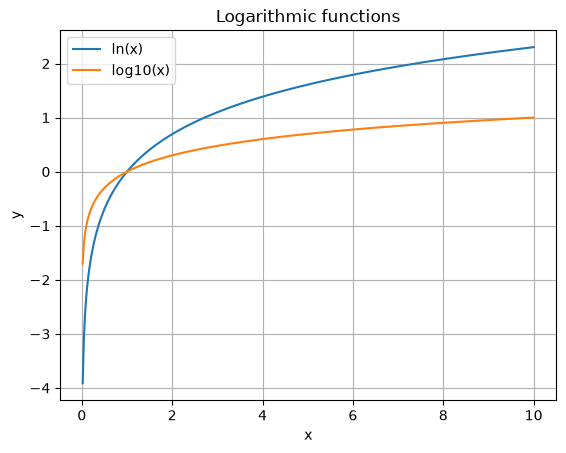

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0.02, 10, 400)
plt.figure()
plt.plot(x, np.log(x), label="ln(x)")
plt.plot(x, np.log10(x), label="log10(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Logarithmic functions")
plt.grid(True)
plt.legend()
plt.show()

## 5. Why logs matter in probability and AI/ML

If independent event probabilities multiply, taking logs converts the product into a sum:

$$
\log\left(\prod_{i=1}^n p_i\right)
=\sum_{i=1}^n\log(p_i).
$$

This is useful for likelihood calculations and avoids multiplying many tiny probabilities directly.

For a true class probability $p$, the negative log-likelihood contribution is $-\log p$. It is small when the model assigns high probability to the true class and large when it assigns low probability.

For a categorical target with one-hot values $y_i$ and predicted probabilities $p_i$, cross-entropy is

$$
H(y,p)=-\sum_i y_i\log(p_i).
$$

When the target is one-hot, this reduces to the negative log of the predicted probability assigned to the correct class. Detailed loss-function derivations belong in the Classical ML and DL threads.

In [6]:
# Illustrate why summing log-probabilities is numerically safer than multiplying many probabilities.
probabilities = [0.01] * 100
direct_product = math.prod(probabilities)
sum_logs = sum(math.log(p) for p in probabilities)

print("Direct product:", direct_product)
print("Log of product:", math.log(direct_product))
print("Sum of logs:", sum_logs)
print("Log-domain result corresponds to:", math.exp(sum_logs))

Direct product: 1.0000000000000017e-200
Log of product: -460.51701859880916
Sum of logs: -460.5170185988091
Log-domain result corresponds to: 1.0000000000000348e-200


## 6. Numerical stability: log-sum-exp preview

Directly computing $\log(e^{a_1}+\cdots+e^{a_n})$ can overflow when values are large. Let $m=\max_i a_i$:

$$
\log\sum_i e^{a_i}
=m+\log\sum_i e^{a_i-m}.
$$

The transformed exponents are at most zero, reducing overflow risk. This is a foundational numerical technique used in stable probabilistic computations.

In [7]:
def logsumexp(values):
    m = max(values)
    return m + math.log(sum(math.exp(v - m) for v in values))

values = [1000, 1001, 999]
print(logsumexp(values))

1001.4076059644444


## 7. Practice

1. Evaluate $\log_2(32)$.
2. Expand $\log(5x^2/y)$ using log laws, assuming positive variables.
3. Solve $e^x=7$.
4. Explain why $\log(a+b)\ne\log a+\log b$ in general.
5. If the probability assigned to the correct class is 0.8, calculate its negative log-likelihood using natural logarithm.
6. Explain why summing log-probabilities is preferable to multiplying many small probabilities.

**Where this appears in AI/ML:** Logarithms are essential for interpreting likelihoods, cross-entropy and stable probability calculations. Understand both the algebra and the numerical reason for using the log domain.